In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.compose import make_column_selector,make_column_transformer
from sklearn.preprocessing import OneHotEncoder,LabelEncoder,OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree, DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, r2_score
from sklearn.preprocessing import StandardScaler, MaxAbsScaler
from sklearn.pipeline import Pipeline
from tqdm import tqdm

In [2]:
df = pd.read_csv("Concrete_Data.csv")
df.head()

,Cement,Blast,Fly,Water,Superplasticizer,Coarse,Fine,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [4]:
X, y = df.drop("Strength",axis=1),df["Strength"]
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=26)

In [5]:
depths = [None,2,3,4,5,6,7]
min_split = [2,0.05,0.01,0.1,0.2,0.3]
min_leaf = [1,0.05,0.01,0.1,0.2,0.3]
scores = []
for d in tqdm(depths):
    for s in min_split:
        for l in min_leaf:
            dtr = DecisionTreeRegressor(random_state=26, max_depth=d, 
                                        min_samples_split=s, min_samples_leaf=l)
            pipe = Pipeline([("TREE",dtr)])
            pipe.fit(X_train,y_train)
            y_pred = pipe.predict(X_test)
            scores.append([d,s,l,r2_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores, columns=["D","S","L","Scores"])
df_scores.sort_values("Scores",ascending=False)

100%|████████████████████████████████████████████████████████████████████████████████████| 7/7 [00:01<00:00,  4.35it/s]


,D,S,L,Scores
0,NaN,2.00,1.0,0.850026
12,NaN,0.01,1.0,0.833292
228,7.0,0.01,1.0,0.797718
180,6.0,2.00,1.0,0.795930
222,7.0,0.05,1.0,0.794303
...,...,...,...,...
125,4.0,0.01,0.3,0.187601
119,4.0,0.05,0.3,0.187601
221,7.0,2.00,0.3,0.187601
17,NaN,0.01,0.3,0.187601


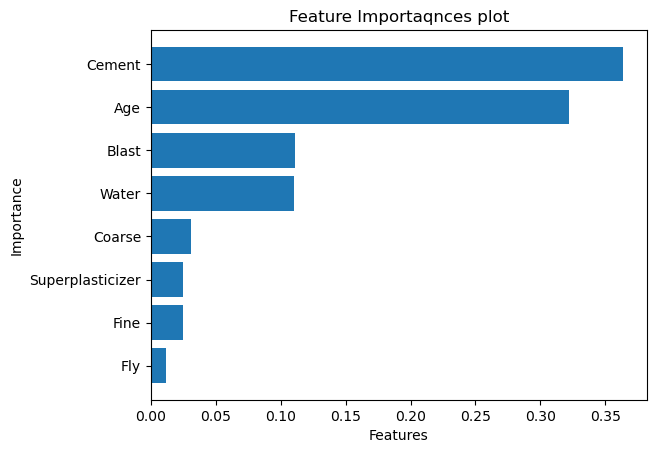

In [9]:
best_tree = DecisionTreeRegressor(random_state=26,max_depth=None,
                                  min_samples_split=2,min_samples_leaf=1)
best_tree.fit(X,y)
df_imp = pd.DataFrame({"features":list(X.columns),
                       "importance": best_tree.feature_importances_})
# plt.figure(figsize=(16,10))
df_imp.sort_values('importance',inplace=True)
plt.barh(df_imp["features"],df_imp["importance"])
plt.title("Feature Importaqnces plot")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.show()